Praktikum 2 - Pra pengolahan data & seleksi fitur (Titanic).

Encoding Sex & Cabin, imputasi Age (median), standarisasi Age,
lalu seleksi 5 fitur: Survived, Pclass, Age, Sex, Cabin.
Output: output/*.png, data/Titanic-Dataset-selected.csv

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("seleksi_fitur.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js03-ektraksi-fitur\praktikum-2


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

HERE = Path(__file__).resolve().parent
DATA = HERE.parent / "data"
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

In [3]:
# Langkah 1 - load data (hasil imputasi praktikum 1)
df = pd.read_csv(DATA / "Titanic-Dataset-fixed.csv")
print("=== Data awal ===")
print(df[["Survived", "Pclass", "Sex", "Age", "Cabin"]].head())

=== Data awal ===
   Survived  Pclass     Sex   Age Cabin
0         0       3    male  22.0  DECK
1         1       1  female  38.0   C85
2         1       3  female  26.0  DECK
3         1       1  female  35.0  C123
4         0       3    male  35.0  DECK


In [4]:
# Langkah 2 - encoding Sex
df["Sex"] = df["Sex"].map({"male": 1, "female": 0})
print("\n=== Setelah encoding 'Sex' ===")
print(df[["Sex"]].head().to_string())


=== Setelah encoding 'Sex' ===
   Sex
0    1
1    0
2    0
3    0
4    1


In [5]:
# Langkah 3 - encoding Cabin -> deck (huruf pertama), lalu label encoding
df["Cabin"] = df["Cabin"].fillna("Unknown")
df["Cabin"] = df["Cabin"].apply(lambda x: x[0] if x != "Unknown" else "U")
print("\n=== Cabin setelah diambil huruf pertama (deck) ===")
print(df[["Cabin"]].head().to_string())
print(f"Deck unik: {sorted(df['Cabin'].unique())}")


=== Cabin setelah diambil huruf pertama (deck) ===
  Cabin
0     D
1     C
2     D
3     C
4     D
Deck unik: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']


In [6]:
# Modul mengimpor LabelEncoder tetapi tidak memakainya, sementara dataset
# Titanic-Dataset-selected.csv bawaan berisi Cabin numerik. Di sini Cabin
# di-label-encode agar konsisten dengan dataset tersebut.
le = LabelEncoder()
df["Cabin"] = le.fit_transform(df["Cabin"])
print(f"Mapping Cabin -> {dict(zip(le.classes_, le.transform(le.classes_)))}")

Mapping Cabin -> {'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2), 'D': np.int64(3), 'E': np.int64(4), 'F': np.int64(5), 'G': np.int64(6), 'T': np.int64(7)}


In [7]:
# Langkah 4 - imputasi Age dengan median
df["Age"] = df[["Age"]].fillna(df["Age"].median())
print("\n=== Age setelah imputasi median ===")
print(df[["Age"]].head(10).to_string())
print(f"median Age = {df['Age'].median():.4f}")


=== Age setelah imputasi median ===
         Age
0  22.000000
1  38.000000
2  26.000000
3  35.000000
4  35.000000
5  29.699118
6  54.000000
7   2.000000
8  27.000000
9  14.000000
median Age = 29.6991


In [8]:
# Langkah 5 - standarisasi Age
scaler = StandardScaler()
df["Age"] = scaler.fit_transform(df[["Age"]])
print("\n=== Age setelah StandardScaler ===")
print(df[["Age"]].head(10).to_string())
print(f"mean={df['Age'].mean():.6f}  std(ddof=1)={df['Age'].std():.6f}")


=== Age setelah StandardScaler ===
        Age
0 -0.592481
1  0.638789
2 -0.284663
3  0.407926
4  0.407926
5  0.000000
6  1.870059
7 -2.131568
8 -0.207709
9 -1.208115
mean=0.000000  std(ddof=1)=1.000562


In [9]:
# Langkah 6 - seleksi fitur
df = df[["Survived", "Pclass", "Age", "Sex", "Cabin"]]
print("\n=== Hasil seleksi fitur ===")
print(df.head().to_string())
print(f"shape = {df.shape}")

df.to_csv(DATA / "Titanic-Dataset-selected.csv", index=False)
print(f"Dataset terseleksi disimpan: {DATA / 'Titanic-Dataset-selected.csv'}")


=== Hasil seleksi fitur ===
   Survived  Pclass       Age  Sex  Cabin
0         0       3 -0.592481    1      3
1         1       1  0.638789    0      2
2         1       3 -0.284663    0      3
3         1       1  0.407926    0      2
4         0       3  0.407926    1      3
shape = (891, 5)
Dataset terseleksi disimpan: C:\code\pemmes26\js03-ektraksi-fitur\data\Titanic-Dataset-selected.csv


Korelasi Survived vs fitur:
Survived    1.0000
Pclass     -0.3385
Age        -0.0698
Sex        -0.5434
Cabin      -0.0998
grafik -> output/p2_korelasi_fitur.png

Selesai praktikum 2.


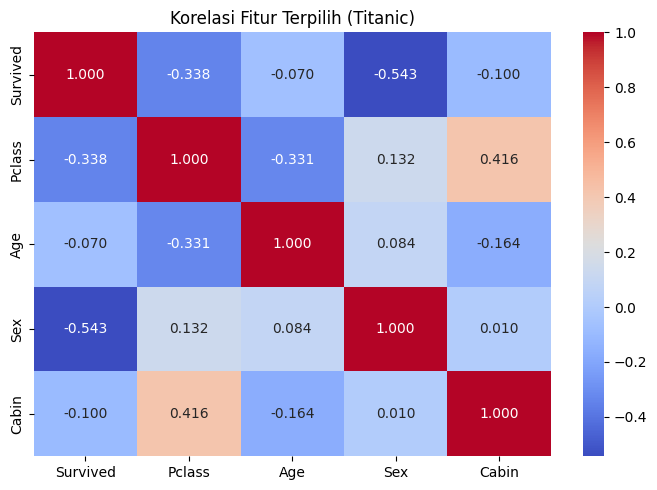

In [10]:
# visualisasi korelasi antar fitur terpilih
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".3f", cmap="coolwarm", ax=ax)
ax.set_title("Korelasi Fitur Terpilih (Titanic)")
fig.tight_layout()
fig.savefig(OUT / "p2_korelasi_fitur.png", dpi=120)
print(f"Korelasi Survived vs fitur:\n{df.corr()['Survived'].round(4).to_string()}")
print("grafik -> output/p2_korelasi_fitur.png")

print("\nSelesai praktikum 2.")